# 🏦 Loan Approval Prediction using Machine Learning
### End-to-End Data Science & Machine Learning Project (Kaggle Loan Prediction Dataset)

---

## 1. Project Introduction (مقدمة المشروع)

### 📌 Project Idea (فكرة المشروع)
Financial institutions and banks receive hundreds of loan applications every day. Manually evaluating each applicant's financial stability, creditworthiness, and demographic profile is time-consuming and prone to human bias. The goal of this project is to build an automated, data-driven **Machine Learning pipeline** that analyzes historical loan application records and accurately predicts whether a new loan application should be **Approved (`Y`)** or **Rejected (`N`)**.

### 📌 What is Loan Prediction? (معنى Loan Prediction)
**Loan Approval Prediction** is the process of assessing the risk associated with lending money to an applicant based on historical data such as:
- **Applicant & Co-applicant Income** (`ApplicantIncome`, `CoapplicantIncome`)
- **Requested Loan Amount & Repayment Term** (`LoanAmount`, `Loan_Amount_Term`)
- **Credit History** (`Credit_History` — whether the applicant has paid off past debts)
- **Demographic & Property Attributes** (`Gender`, `Married`, `Dependents`, `Education`, `Self_Employed`, `Property_Area`)

### 📌 Type of Machine Learning Problem (نوع المشكلة)
This problem is a **Supervised Machine Learning — Binary Classification** problem:
- **Supervised Learning:** Because we train our models on labeled historical data where the actual outcome (`Loan_Status`) is already known.
- **Binary Classification:** Because the target variable `Loan_Status` consists of only two discrete categories:
  - `Y` (**1**): Loan Approved (تمت الموافقة على القرض)
  - `N` (**0**): Loan Not Approved (تم رفض القرض)

### 📌 Difference Between Classification and Regression (الفرق بين التصنيف والانحدار)
| Aspect | Classification (التصنيف) | Regression (الانحدار) |
| :--- | :--- | :--- |
| **Target Variable Type** | Discrete / Categorical labels (e.g., `0` or `1`, `Yes` or `No`, `Spam` or `Not Spam`) | Continuous numerical values (e.g., House Price, Temperature, Sales Revenue) |
| **Output Nature** | Class membership or class probability $P(y=1|X) \in [0, 1]$ | Unbounded real number $\hat{y} \in (-\infty, +\infty)$ |
| **Decision Boundary** | Separates data points into distinct classes | Fits a best-fit line/hyperplane to estimate continuous quantities |
| **Evaluation Metrics** | Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrix | R² Score, MAE, MSE, RMSE |

### 📌 Why is `Loan_Status` a Categorical Target? (سبب اعتبار `Loan_Status` متغيرًا تصنيفيًا)
`Loan_Status` represents a qualitative decision (`Approved` vs. `Not Approved`), not a continuous quantity. Even after encoding `Y -> 1` and `N -> 0`, the numbers `0` and `1` represent categorical states rather than a continuous scale (for example, a loan status of `0.65` or `1.4` does not exist in reality—a loan is either approved or rejected).

### 📌 Models Used in This Project (النماذج المستخدمة)
1. **Linear Regression (with a `0.5` Threshold) — *[Required]*:**
   - Although Linear Regression is a regression algorithm that outputs continuous predictions $\hat{y}$, it is included per project requirements. Its continuous predictions are converted into binary classes (`0` and `1`) using a decision threshold of `0.5`:
     $$\hat{y}_{\text{class}} = \begin{cases} 1 & \text{if } \hat{y} \ge 0.5 \\ 0 & \text{if } \hat{y} < 0.5 \end{cases}$$
2. **Decision Tree Classifier — *[Required]*:**
   - A non-linear, tree-structured classifier that splits features using information gain / Gini impurity to create interpretable decision rules.
3. **Random Forest Classifier — *[Required]*:**
   - An ensemble learning method (Bagging) that combines multiple Decision Trees to reduce variance (overfitting) and improve generalization accuracy.
4. **Logistic Regression — *[Additional Benchmark Model]*:**
   - Included as an **additional model** (نموذج إضافي وليس بديلًا عن النماذج المطلوبة) because it is the natural statistical counterpart to Linear Regression for binary classification, using the Sigmoid function $\sigma(z) = \frac{1}{1 + e^{-z}}$ to bound probabilities strictly between `0` and `1`.

### 📌 Evaluation Metrics (مقاييس التقييم)
Because loan approval datasets are moderately imbalanced (more approved loans than rejected loans), relying on Accuracy alone is insufficient. We evaluate all models using:
- **Accuracy:** Overall percentage of correct predictions.
- **Precision:** Out of all applicants predicted as *Approved*, what proportion were actually worthy of approval? (Minimizes False Positives / risky bad loans).
- **Recall (Sensitivity):** Out of all genuinely creditworthy applicants, what proportion did the model successfully approve? (Minimizes False Negatives).
- **F1-Score:** Harmonic mean of Precision and Recall ($2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$).
- **Confusion Matrix & ROC-AUC Score:** Visualizes True/False Positives and Negatives and measures discriminative power across thresholds.

---
## 2. Importing Libraries (استيراد المكتبات)

First, we provide an optional (commented-out) cell to install the required packages if they are not already installed in your environment. Then, we import all necessary libraries for data manipulation, visualization, preprocessing, modeling, and evaluation.

In [1]:
# Optional: Uncomment the line below to install libraries if they are not installed in your environment
# خلية اختيارية لتثبيت المكتبات في حال عدم توفرها (معلّقة)
# !pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
# Data Manipulation & Numerical Computation (معالجة البيانات والعمليات الحسابية)
import os
import warnings
import numpy as np
import pandas as pd

# Data Visualization (الرسوم البيانية)
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: Preprocessing, Splitting, Models, and Evaluation Metrics
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning Models (النماذج المطلوبة + النموذج الإضافي)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics (مقاييس التقييم)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    mean_squared_error,
    r2_score
)

# Configure visual style and suppress unnecessary warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


---
## 3. Loading the Dataset (تحميل البيانات)

We load the official Kaggle dataset file `train_u6lujuX_CVtuZ9i.csv` from the local workspace (`train_u6lujuX_CVtuZ9i.csv` or `data/train_u6lujuX_CVtuZ9i.csv`).
- **Source:** [Kaggle - Loan Prediction Problem Dataset](https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset)
- If the file is missing, the code displays a clear instruction explaining where to place or upload the dataset (no synthetic or random data is ever generated).

In [3]:
# Define candidate local paths for the training dataset
# تحديد المسارات المحتملة لملف البيانات الحقيقي
file_name = "train_u6lujuX_CVtuZ9i.csv"
candidate_paths = [
    file_name,
    os.path.join("data", file_name),
    os.path.join("..", "data", file_name)
]

dataset_path = None
for path in candidate_paths:
    if os.path.exists(path):
        dataset_path = path
        break

if dataset_path is not None:
    df = pd.read_csv(dataset_path)
    print(f"✅ Dataset loaded successfully from: '{dataset_path}'")
    print(f"📊 Total Records: {df.shape[0]} rows | Total Columns: {df.shape[1]} columns")
else:
    print("❌ ERROR: Dataset file 'train_u6lujuX_CVtuZ9i.csv' was NOT found!")
    print("📌 Please download 'train_u6lujuX_CVtuZ9i.csv' from Kaggle:")
    print("   https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset")
    print(f"📌 Place the file in the current working directory: {os.getcwd()}")
    print("   OR inside the 'data/' subfolder, then re-run this cell.")
    # Optional Google Colab upload helper if running on Colab:
    # from google.colab import files
    # uploaded = files.upload()
    raise FileNotFoundError("Please provide 'train_u6lujuX_CVtuZ9i.csv' to proceed.")

✅ Dataset loaded successfully from: 'train_u6lujuX_CVtuZ9i.csv'
📊 Total Records: 614 rows | Total Columns: 13 columns


### 3.1 Display First 5 Rows (`head()`)
Viewing the first 5 records helps us verify that the columns and values were parsed properly.

In [4]:
# Display the first 5 rows of the dataset (عرض أول 5 صفوف)
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


### 3.2 Display Last 5 Rows (`tail()`)
Viewing the last 5 records confirms data consistency down to the end of the file.

In [5]:
# Display the last 5 rows of the dataset (عرض آخر 5 صفوف)
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


### 3.3 Dataset Dimensions (`shape`) and Column Names (`columns`)
Checking the exact number of rows (samples) and columns (features + target), as well as the column names.

In [6]:
# Display dataset shape and column names (عرض أبعاد البيانات وأسماء الأعمدة)
print(f"Dataset Shape (Rows, Columns): {df.shape}")
print(f"Number of Rows (Applicants)  : {df.shape[0]}")
print(f"Number of Columns (Features) : {df.shape[1]}")
print("\nColumn Names:")
for idx, col in enumerate(df.columns, 1):
    print(f"  {idx:2d}. {col}")

Dataset Shape (Rows, Columns): (614, 13)
Number of Rows (Applicants)  : 614
Number of Columns (Features) : 13

Column Names:
   1. Loan_ID
   2. Gender
   3. Married
   4. Dependents
   5. Education
   6. Self_Employed
   7. ApplicantIncome
   8. CoapplicantIncome
   9. LoanAmount
  10. Loan_Amount_Term
  11. Credit_History
  12. Property_Area
  13. Loan_Status


### 3.4 Dataset Structure & Data Types (`info()`)
Using `df.info()` to inspect data types (`object`, `int64`, `float64`) and non-null counts per column.

In [7]:
# Inspect data types and non-null counts (فحص أنواع البيانات والقيم غير الفارغة)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


### 3.5 Statistical Summary (`describe(include="all").T`)
Using `df.describe(include="all").T` to inspect summary statistics for both **numerical** columns (mean, std, min, quartiles, max) and **categorical** columns (unique count, top/mode category, frequency).

In [8]:
# Comprehensive statistical summary of all columns (ملخص إحصائي شامل لجميع الأعمدة)
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


---
## 4. Understanding the Data (فهم البيانات)

### 📌 Description of Each Column in the Dataset (شرح وظيفة كل عمود)

| # | Column Name | Data Type | Role | Description (English & Arabic) |
| :-: | :--- | :--- | :--- | :--- |
| 1 | **`Loan_ID`** | Categorical (`object`) | Identifier | Unique loan application ID (e.g., `LP001002`). Used only for identification; has no predictive power (معرّف فريد للطلب ولا يفيد في التنبؤ). |
| 2 | **`Gender`** | Categorical (`object`) | Feature | Applicant's gender: `Male` or `Female` (جنس المتقدم للطلب). |
| 3 | **`Married`** | Categorical (`object`) | Feature | Marital status of the applicant: `Yes` or `No` (الحالة الاجتماعية: متزوج أم لا). |
| 4 | **`Dependents`** | Categorical/Ordinal (`object`) | Feature | Number of dependents supported by the applicant: `0`, `1`, `2`, or `3+` (عدد المعالين). |
| 5 | **`Education`** | Categorical (`object`) | Feature | Applicant's education level: `Graduate` or `Not Graduate` (المستوى التعليمي: خريج جامعي أم لا). |
| 6 | **`Self_Employed`** | Categorical (`object`) | Feature | Whether the applicant is self-employed: `Yes` or `No` (هل يعمل لحسابه الخاص). |
| 7 | **`ApplicantIncome`** | Numerical (`int64`) | Feature | Primary applicant's monthly income (دخل المتقدم الأساسي). |
| 8 | **`CoapplicantIncome`** | Numerical (`float64`) | Feature | Co-applicant's monthly income, if any (دخل المتقدم المشارك أو الزوج/الزوجة). |
| 9 | **`LoanAmount`** | Numerical (`float64`) | Feature | Loan amount requested in thousands (مبلغ القرض المطلوب بالآلاف). |
| 10 | **`Loan_Amount_Term`** | Numerical (`float64`) | Feature | Repayment period of the loan in months, e.g., `360` months = 30 years (مدة سداد القرض بالأشهر). |
| 11 | **`Credit_History`** | Binary/Numerical (`float64`) | Feature | Credit history meets guidelines: `1.0` = Good credit history, `0.0` = Bad credit history (السجل الائتماني للعميل). |
| 12 | **`Property_Area`** | Categorical (`object`) | Feature | Location category of the property: `Urban`, `Semiurban`, or `Rural` (منطقة العقار: حضرية، شبه حضرية، ريفية). |
| 13 | **`Loan_Status`** | Binary Categorical (`object`) | **Target ($y$)** | Whether the loan was approved: `Y` = Approved, `N` = Not Approved (حالة الموافقة على القرض - المتغير الهدف). |

### 4.1 Unique Values, Missing Values Count, and Missing Percentage per Column
Let's create a clean summary table showing the data type, number of unique values, number of missing values, and percentage of missing values for each column.

In [9]:
# Calculate unique values, missing values count, and missing percentage per column
# حساب عدد القيم الفريدة وعدد ونسبة القيم المفقودة في كل عمود
data_understanding_df = pd.DataFrame({
    "Data_Type": df.dtypes,
    "Total_Rows": len(df),
    "Non_Null_Count": df.notnull().sum(),
    "Unique_Values": df.nunique(),
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage (%)": (df.isnull().sum() / len(df) * 100).round(2)
})

# Sort by Missing_Count descending to highlight columns needing imputation
data_understanding_df.sort_values(by="Missing_Count", ascending=False)

,Data_Type,Total_Rows,Non_Null_Count,Unique_Values,Missing_Count,Missing_Percentage (%)
Credit_History,float64,614,564,2,50,8.14
Self_Employed,str,614,582,2,32,5.21
LoanAmount,float64,614,592,203,22,3.58
Dependents,str,614,599,4,15,2.44
Loan_Amount_Term,float64,614,600,10,14,2.28
Gender,str,614,601,2,13,2.12
Married,str,614,611,2,3,0.49
Education,str,614,614,2,0,0.00
Loan_ID,str,614,614,614,0,0.00
CoapplicantIncome,float64,614,614,287,0,0.00


### 4.2 Distribution of the Target Variable (`Loan_Status`)
Let's inspect the exact counts and percentages of `Loan_Status` (`Y` vs `N`).

In [10]:
# Distribution of the target variable Loan_Status (توزيع المتغير الهدف)
target_counts = df["Loan_Status"].value_counts(dropna=False)
target_pct = (df["Loan_Status"].value_counts(normalize=True, dropna=False) * 100).round(2)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_pct
})
target_summary.index = ["Y (Approved)", "N (Not Approved)"]
print("📌 Target Variable Distribution (Loan_Status):")
display(target_summary)

📌 Target Variable Distribution (Loan_Status):


,Count,Percentage (%)
Y (Approved),422,68.73
N (Not Approved),192,31.27


**🔎 Observations on Data Structure & Target Distribution:**
- The dataset contains **614 loan applications** and **13 columns**.
- **7 columns have missing values:** `Credit_History` has the highest missing rate (**50 missing values, 8.14%**), followed by `Self_Employed` (**32, 5.21%**), `LoanAmount` (**22, 3.58%**), `Dependents` (**15, 2.44%**), `Loan_Amount_Term` (**14, 2.28%**), `Gender` (**13, 2.12%**), and `Married` (**3, 0.49%**).
- **Target Variable (`Loan_Status`):** Has **0 missing values**. Out of 614 applications, **422 (68.73%)** were approved (`Y`) and **192 (31.27%)** were rejected (`N`). This shows a moderate class imbalance (~2.2 : 1 ratio in favor of approvals), which means we must use `stratify=y` during splitting and monitor **F1-Score, Precision, Recall, and ROC-AUC** alongside Accuracy.

---
## 5. Exploratory Data Analysis — EDA (التحليل الاستكشافي للبيانات)

In this section, we visually explore the dataset using 10 clear, well-labeled charts divided into logical groups:
1. **Group A (Categorical Features vs. Target — Plots 1 to 5):**
   - Plot 1: Count plot of `Loan_Status`
   - Plot 2: Count plot of `Education` vs. `Loan_Status`
   - Plot 3: Count plot of `Credit_History` vs. `Loan_Status`
   - Plot 4: Count plot of `Property_Area` vs. `Loan_Status`
   - Plot 5: Count plot of `Married` vs. `Loan_Status`
2. **Group B (Numerical Distributions — Plots 6 & 7):**
   - Plot 6: Histogram of `ApplicantIncome`
   - Plot 7: Histogram of `LoanAmount`
3. **Group C (Boxplots of Numerical Features by `Loan_Status` — Plots 8 & 9):**
   - Plot 8: Boxplot of `ApplicantIncome` by `Loan_Status`
   - Plot 9: Boxplot of `LoanAmount` by `Loan_Status`
4. **Group D (Multivariate Correlation Analysis — Plot 10):**
   - Plot 10: Correlation Heatmap of Numerical Variables

### 5.1 Plot 1: Count Plot of Target Variable (`Loan_Status`)

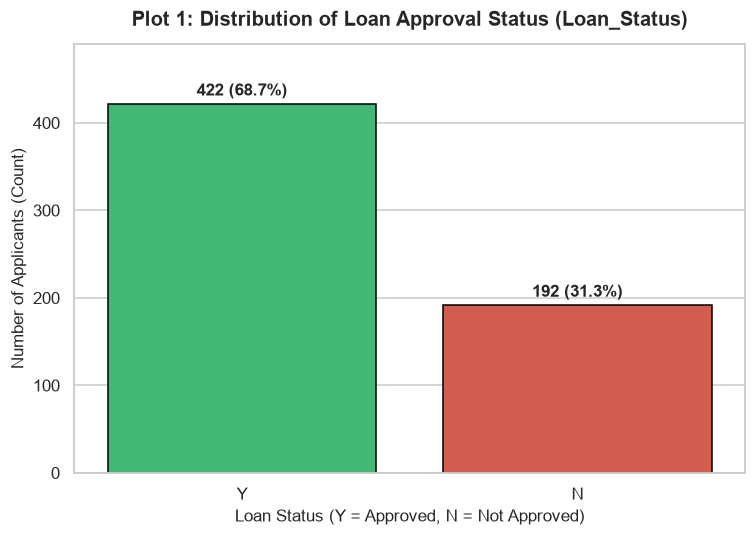

In [11]:
# Plot 1: Count plot for Loan_Status (رسم بياني لتوزيع حالة القرض)
fig, ax = plt.subplots(figsize=(7, 5))
palette_target = {"Y": "#2ecc71", "N": "#e74c3c"}
sns.countplot(data=df, x="Loan_Status", palette=palette_target, ax=ax, edgecolor="black")

for container in ax.containers:
    ax.bar_label(container, fmt=lambda x: f"{int(x)} ({x/len(df)*100:.1f}%)", fontsize=11, fontweight="bold", padding=3)

ax.set_title("Plot 1: Distribution of Loan Approval Status (Loan_Status)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Loan Status (Y = Approved, N = Not Approved)", fontsize=11)
ax.set_ylabel("Number of Applicants (Count)", fontsize=11)
ax.set_ylim(0, 490)
plt.tight_layout()
plt.show()

### 5.2 Plots 2, 3, 4, and 5: Categorical Features vs. `Loan_Status`
Let's visualize how `Education`, `Credit_History`, `Property_Area`, and `Married` relate to loan approval (`Loan_Status`).

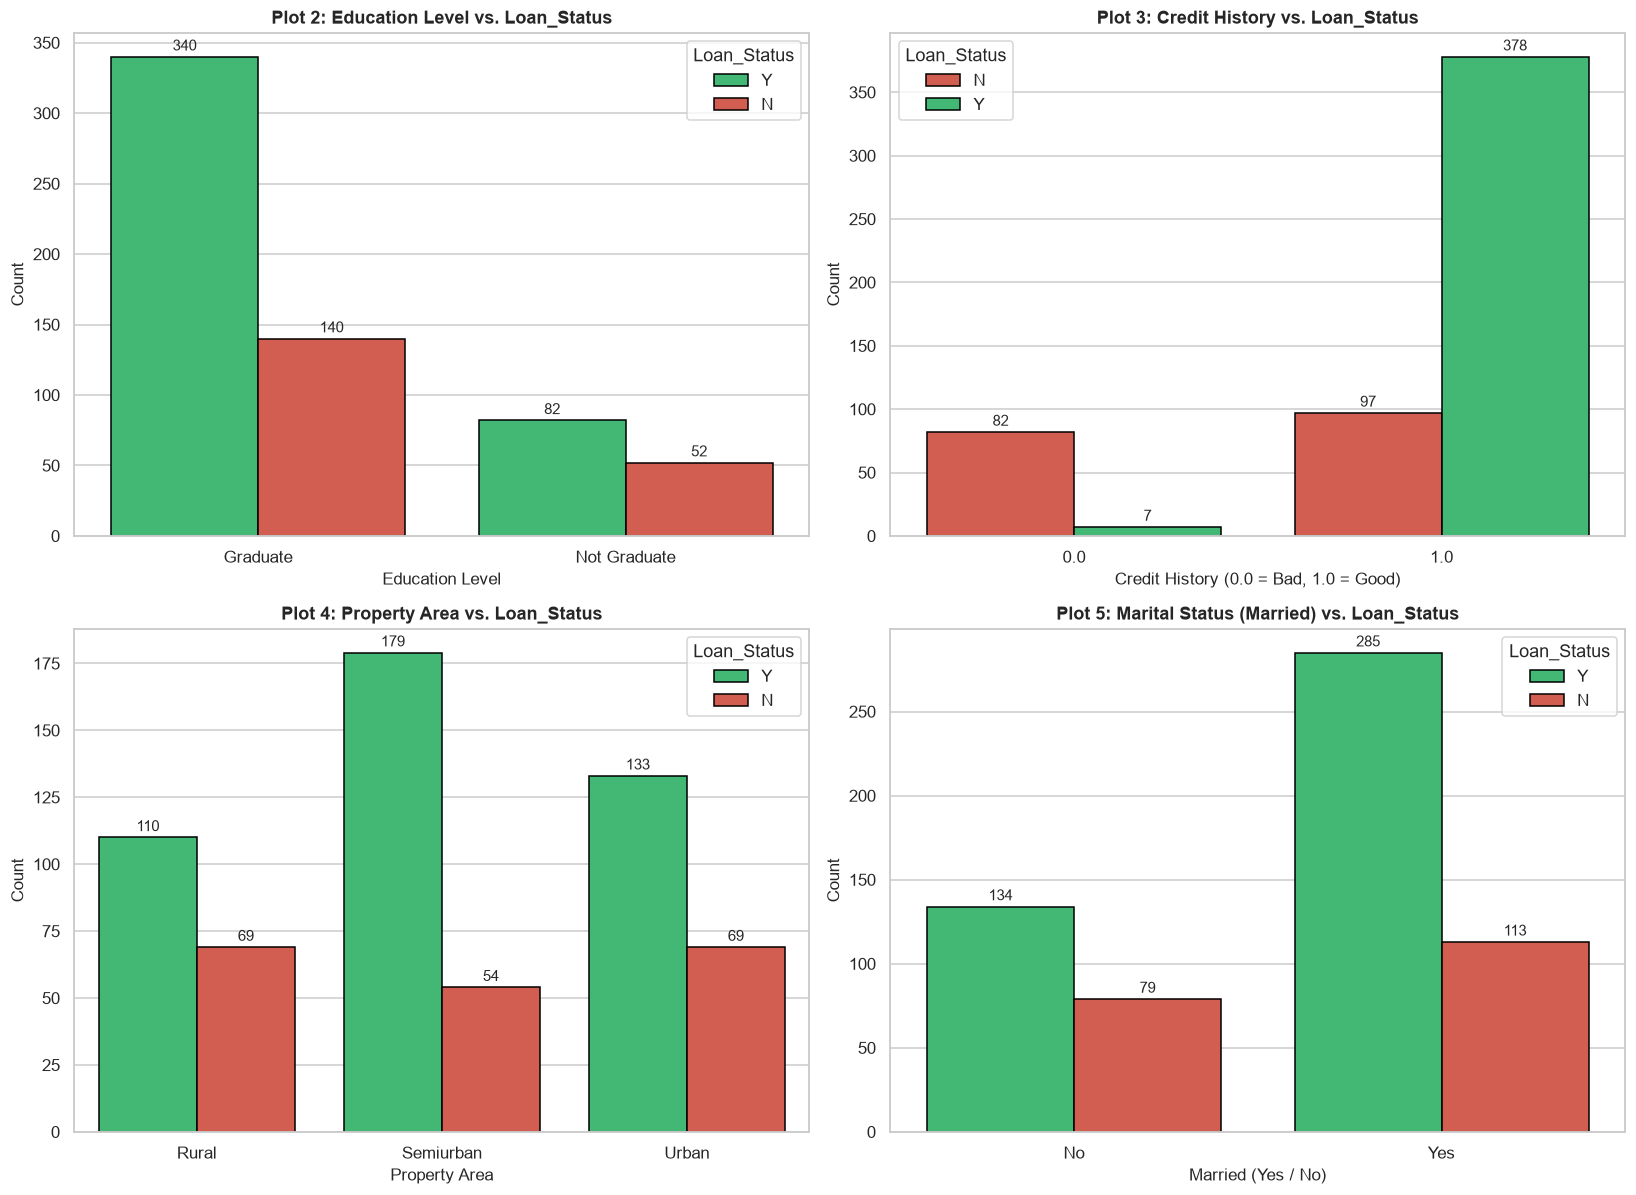

In [12]:
# Plots 2, 3, 4, 5: Count plots for Categorical Variables vs Loan_Status
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
palette_target = {"Y": "#2ecc71", "N": "#e74c3c"}

# Plot 2: Education vs Loan_Status
sns.countplot(data=df, x="Education", hue="Loan_Status", palette=palette_target, ax=axes[0, 0], edgecolor="black")
axes[0, 0].set_title("Plot 2: Education Level vs. Loan_Status", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Education Level", fontsize=11)
axes[0, 0].set_ylabel("Count", fontsize=11)
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fontsize=10, padding=2)

# Plot 3: Credit_History vs Loan_Status
sns.countplot(data=df, x="Credit_History", hue="Loan_Status", palette=palette_target, ax=axes[0, 1], edgecolor="black")
axes[0, 1].set_title("Plot 3: Credit History vs. Loan_Status", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Credit History (0.0 = Bad, 1.0 = Good)", fontsize=11)
axes[0, 1].set_ylabel("Count", fontsize=11)
for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container, fontsize=10, padding=2)

# Plot 4: Property_Area vs Loan_Status
sns.countplot(data=df, x="Property_Area", hue="Loan_Status", order=["Rural", "Semiurban", "Urban"], palette=palette_target, ax=axes[1, 0], edgecolor="black")
axes[1, 0].set_title("Plot 4: Property Area vs. Loan_Status", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Property Area", fontsize=11)
axes[1, 0].set_ylabel("Count", fontsize=11)
for container in axes[1, 0].containers:
    axes[1, 0].bar_label(container, fontsize=10, padding=2)

# Plot 5: Married vs Loan_Status
sns.countplot(data=df, x="Married", hue="Loan_Status", palette=palette_target, ax=axes[1, 1], edgecolor="black")
axes[1, 1].set_title("Plot 5: Marital Status (Married) vs. Loan_Status", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Married (Yes / No)", fontsize=11)
axes[1, 1].set_ylabel("Count", fontsize=11)
for container in axes[1, 1].containers:
    axes[1, 1].bar_label(container, fontsize=10, padding=2)

plt.tight_layout()
plt.show()

**🔎 Key Observations from Plots 1–5 (الملاحظات المستخلصة من الرسوم البيانية الفئوية):**
1. **`Loan_Status` (Plot 1):** `422` applications (`68.7%`) were approved (`Y`), while `192` applications (`31.3%`) were rejected (`N`).
2. **`Education` vs. `Loan_Status` (Plot 2):**
   - Out of `480` Graduate applicants, `340` (`70.83%`) were approved and `140` (`29.17%`) were rejected.
   - Out of `134` Not Graduate applicants, `82` (`61.19%`) were approved and `52` (`38.81%`) were rejected. Graduates have a noticeably higher approval rate (`+9.6%`).
3. **`Credit_History` vs. `Loan_Status` (Plot 3):**
   - This is the strongest visual separator in the entire dataset:
   - Among applicants with `Credit_History = 1.0` (475 applicants), **378 (`79.58%`) were approved** and only 97 (`20.42%`) were rejected.
   - Among applicants with `Credit_History = 0.0` (89 applicants), **82 (`92.13%`) were rejected** and only 7 (`7.87%`) were approved.
4. **`Property_Area` vs. `Loan_Status` (Plot 4):**
   - **Semiurban** properties have the highest approval rate: `179` approved vs. `54` rejected (`76.82%` approval rate).
   - **Urban** properties have `133` approved vs. `69` rejected (`65.84%` approval rate).
   - **Rural** properties have the lowest approval rate: `110` approved vs. `69` rejected (`61.45%` approval rate).
5. **`Married` vs. `Loan_Status` (Plot 5):**
   - Married applicants (`Yes`) show a higher approval rate (`285` approved vs. `113` rejected, or `71.61%`) compared to unmarried applicants (`No`: `134` approved vs. `79` rejected, or `62.91%`).

### 5.3 Plots 6 and 7: Histograms of `ApplicantIncome` and `LoanAmount`
Let's examine the distribution, skewness, and spread of the numerical variables `ApplicantIncome` and `LoanAmount`.

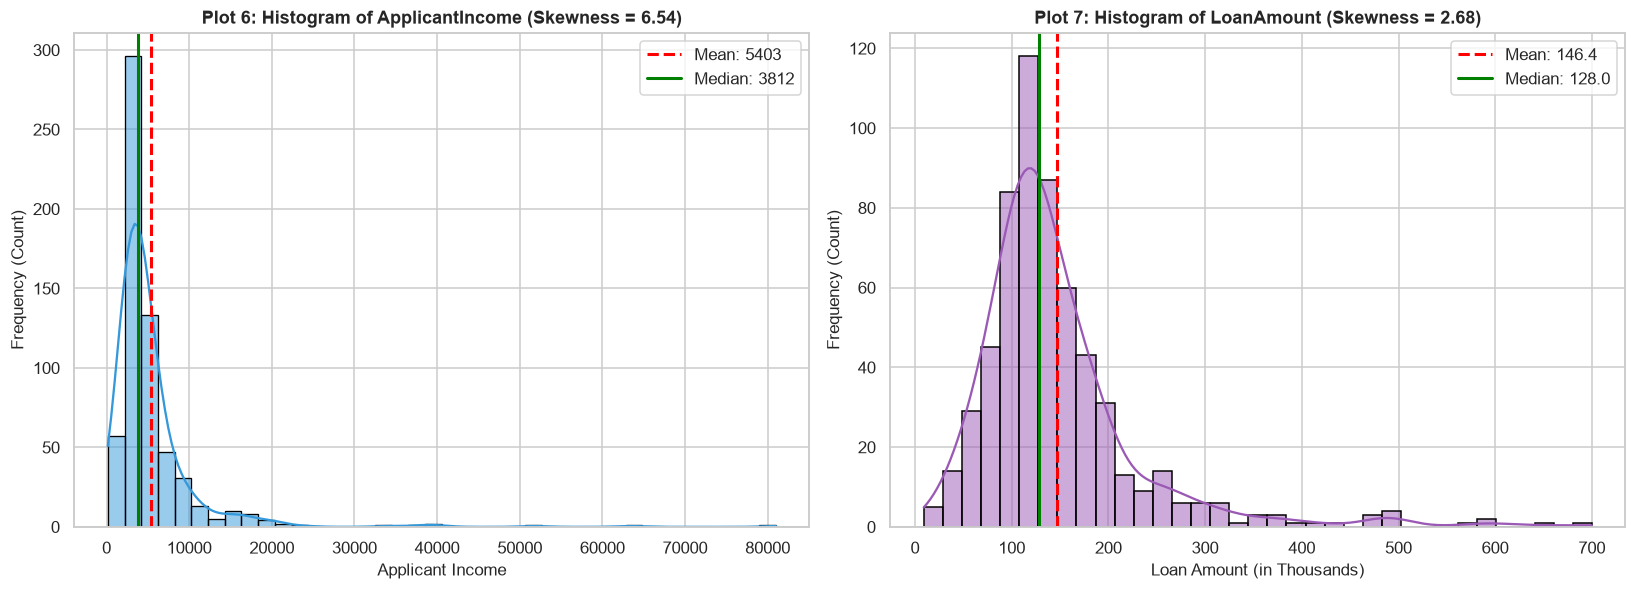

In [13]:
# Plots 6 & 7: Histograms for ApplicantIncome and LoanAmount
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 6: Histogram of ApplicantIncome
sns.histplot(df["ApplicantIncome"], bins=40, kde=True, color="#3498db", edgecolor="black", ax=axes[0])
axes[0].axvline(df["ApplicantIncome"].mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: {df['ApplicantIncome'].mean():.0f}")
axes[0].axvline(df["ApplicantIncome"].median(), color="green", linestyle="-", linewidth=2, label=f"Median: {df['ApplicantIncome'].median():.0f}")
axes[0].set_title(f"Plot 6: Histogram of ApplicantIncome (Skewness = {df['ApplicantIncome'].skew():.2f})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Applicant Income", fontsize=11)
axes[0].set_ylabel("Frequency (Count)", fontsize=11)
axes[0].legend()

# Plot 7: Histogram of LoanAmount
sns.histplot(df["LoanAmount"].dropna(), bins=35, kde=True, color="#9b59b6", edgecolor="black", ax=axes[1])
axes[1].axvline(df["LoanAmount"].mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: {df['LoanAmount'].mean():.1f}")
axes[1].axvline(df["LoanAmount"].median(), color="green", linestyle="-", linewidth=2, label=f"Median: {df['LoanAmount'].median():.1f}")
axes[1].set_title(f"Plot 7: Histogram of LoanAmount (Skewness = {df['LoanAmount'].skew():.2f})", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Loan Amount (in Thousands)", fontsize=11)
axes[1].set_ylabel("Frequency (Count)", fontsize=11)
axes[1].legend()

plt.tight_layout()
plt.show()

**🔎 Key Observations from Plots 6 & 7 (الملاحظات المستخلصة من المدرجات التكرارية):**
1. **`ApplicantIncome` (Plot 6):**
   - Strongly **right-skewed (positively skewed)** with a skewness of **6.54**.
   - Most applicants earn between `1,500` and `6,000` (Median = `3,812.5`), while a small number of high-income applicants earn up to `81,000`, pulling the Mean up to `5,403.5`.
2. **`LoanAmount` (Plot 7):**
   - Also **right-skewed** with a skewness of **2.68**.
   - Most loan requests fall between `90` and `180` thousand (Median = `128.0` thousand, Mean = `146.4` thousand), with a right tail reaching up to `700` thousand.
3. **Implication for Data Cleaning:** Because numerical distributions are right-skewed and contain extreme high values, **Median Imputation** is much more robust than Mean Imputation for filling missing values!

### 5.4 Plots 8 and 9: Boxplots of `ApplicantIncome` and `LoanAmount` by `Loan_Status`
Let's compare the quartiles, medians, and outliers of `ApplicantIncome` and `LoanAmount` across approved (`Y`) and rejected (`N`) loans.

📌 Exact Medians by Loan_Status:


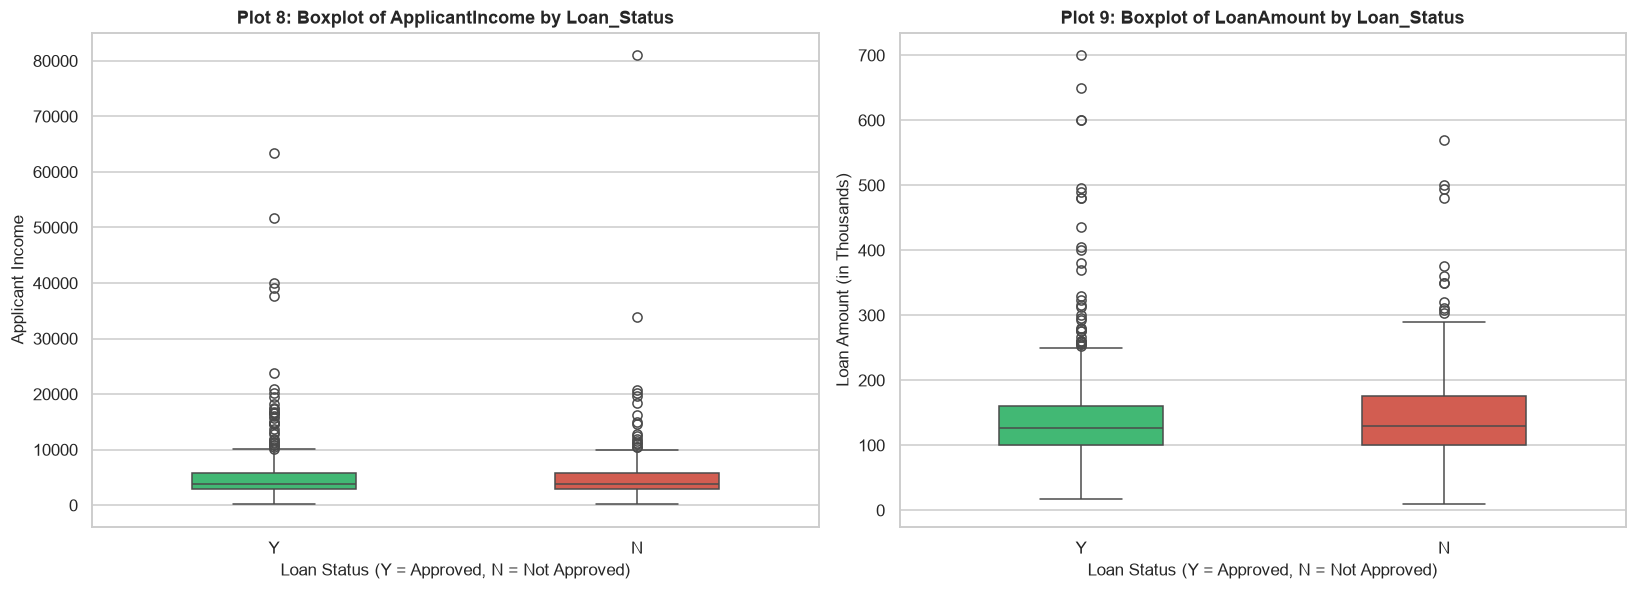

,ApplicantIncome,LoanAmount
Loan_Status,,
N,3833.5,129.0
Y,3812.5,126.0


In [14]:
# Plots 8 & 9: Boxplots of ApplicantIncome and LoanAmount grouped by Loan_Status
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
palette_target = {"Y": "#2ecc71", "N": "#e74c3c"}

# Plot 8: Boxplot of ApplicantIncome by Loan_Status
sns.boxplot(data=df, x="Loan_Status", y="ApplicantIncome", palette=palette_target, ax=axes[0], width=0.45)
axes[0].set_title("Plot 8: Boxplot of ApplicantIncome by Loan_Status", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Loan Status (Y = Approved, N = Not Approved)", fontsize=11)
axes[0].set_ylabel("Applicant Income", fontsize=11)

# Plot 9: Boxplot of LoanAmount by Loan_Status
sns.boxplot(data=df, x="Loan_Status", y="LoanAmount", palette=palette_target, ax=axes[1], width=0.45)
axes[1].set_title("Plot 9: Boxplot of LoanAmount by Loan_Status", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Loan Status (Y = Approved, N = Not Approved)", fontsize=11)
axes[1].set_ylabel("Loan Amount (in Thousands)", fontsize=11)

plt.tight_layout()
plt.show()

# Print exact median & IQR by Loan_Status to support the visual observations
print("📌 Exact Medians by Loan_Status:")
display(df.groupby("Loan_Status")[["ApplicantIncome", "LoanAmount"]].median())

**🔎 Key Observations from Plots 8 & 9 (الملاحظات المستخلصة من مخططات الصندوق Boxplots):**
1. **`ApplicantIncome` by `Loan_Status` (Plot 8):**
   - The median income of approved applicants (`3,813.5`) and rejected applicants (`3,833.5`) is nearly identical, and both groups contain high-income outliers (`> 20,000`, up to `81,000`).
   - This shows that a high `ApplicantIncome` alone does **not** automatically guarantee loan approval (e.g., if `Credit_History` is bad or the requested loan is disproportionately high).
2. **`LoanAmount` by `Loan_Status` (Plot 9):**
   - The median `LoanAmount` for approved loans (`126.0` thousand) and rejected loans (`129.0` thousand) is also very close, though rejected loans have a slightly wider interquartile range at the upper end. Both classes exhibit upper outliers above `300` thousand.

### 5.5 Plot 10: Correlation Heatmap of Numerical Variables
To include `Loan_Status` and `Dependents` in the numerical correlation analysis alongside `ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`, `Loan_Amount_Term`, and `Credit_History`, we compute the Pearson correlation matrix on a temporary numeric view before permanent data cleaning in Section 6.

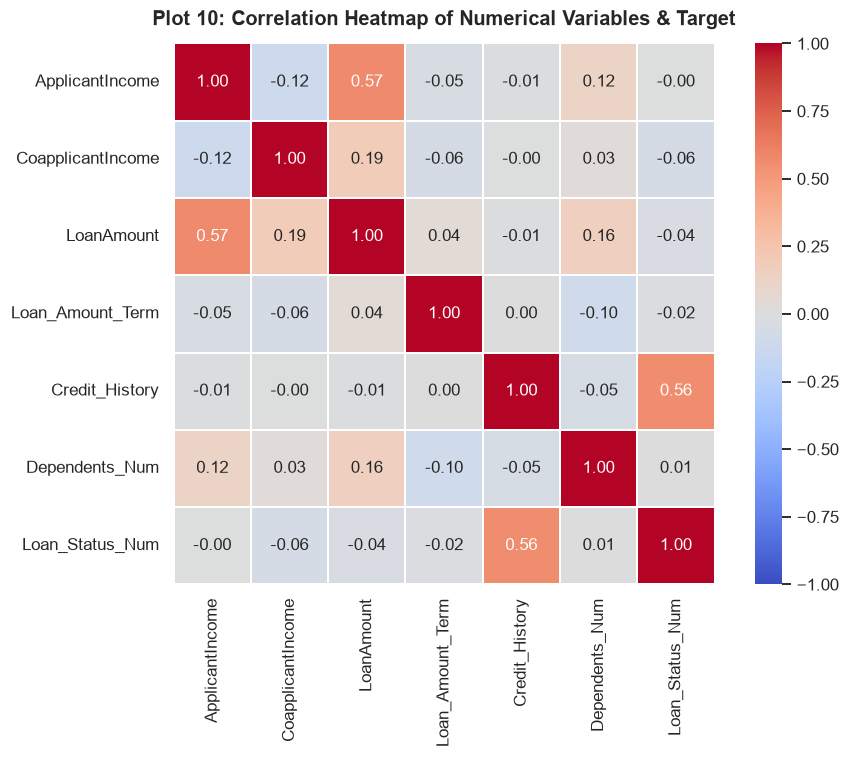

In [15]:
# Plot 10: Correlation Heatmap for Numerical Variables (خريطة الارتباط الحرارية للمتغيرات الرقمية)
df_corr_temp = df.copy()
df_corr_temp["Loan_Status_Num"] = df_corr_temp["Loan_Status"].map({"Y": 1, "N": 0})
df_corr_temp["Dependents_Num"] = df_corr_temp["Dependents"].replace("3+", "3").astype(float)

numeric_cols_for_corr = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History",
    "Dependents_Num",
    "Loan_Status_Num"
]

corr_matrix = df_corr_temp[numeric_cols_for_corr].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=1,
    square=True,
    ax=ax
)
ax.set_title("Plot 10: Correlation Heatmap of Numerical Variables & Target", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

**🔎 Key Observations from Plot 10 (الملاحظات المستخلصة من خريطة الارتباط Heatmap):**
1. **`Credit_History` vs. `Loan_Status_Num` ($r = +0.56$):**
   - Strongest positive linear correlation with loan approval (`0.56`). Applicants with a good credit history (`1.0`) are far more likely to have their loans approved.
2. **`ApplicantIncome` vs. `LoanAmount` ($r = +0.57$):**
   - Moderate-to-strong positive correlation (`0.57`), confirming that applicants with higher incomes typically apply for larger loan amounts.
3. **`CoapplicantIncome` vs. `LoanAmount` ($r = +0.19$):**
   - Weak positive correlation (`0.19`) with `LoanAmount`, as higher combined household income supports slightly larger loans.
4. **`Dependents_Num` vs. `LoanAmount` ($r = +0.16$):**
   - Slight positive correlation (`0.16`) with `LoanAmount`.
5. **Other Numerical Variables vs. `Loan_Status_Num`:**
   - `ApplicantIncome` ($r = -0.00$), `CoapplicantIncome` ($r = -0.06$), `LoanAmount` ($r = -0.04$), and `Loan_Amount_Term` ($r = -0.02$) have near-zero standalone linear correlation with `Loan_Status`, confirming that non-linear interactions (captured by Decision Trees and Random Forests) and `Credit_History` drive the decision.

---
## 6. Data Cleaning (تنظيف البيانات)

We now execute all required Data Cleaning steps systematically:
1. **Drop `Loan_ID`**: Because it is a unique row identifier (`LP001002`, etc.) and not a predictive feature.
2. **Convert `Loan_Status`**: Encode `Y -> 1` and `N -> 0`.
3. **Clean `Dependents` (`3+`)**: Convert `'3+'` into `'3'` and cast `Dependents` to numeric so models can use its ordinal nature (`0 < 1 < 2 < 3`).
4. **Check Duplicate Rows**: Verify whether any duplicate records exist.
5. **Check Illogical Values**: Verify that incomes, loan amounts, and loan terms have no negative or impossible values.
6. **Outlier Inspection & Justification**: Inspect outliers and explain why we do **not** drop them blindly.
7. **Handle Missing Values Without Data Leakage**:
   - **Numerical columns:** Median Imputation.
   - **Categorical columns:** Mode (Most Frequent) Imputation.
   - **Preventing Data Leakage (منع تسرب البيانات):** To ensure **zero Data Leakage** from the test set into the training set, we determine the exact training indices (using the stratified 80/20 split `random_state=42`) and compute all imputation medians and modes **exclusively from the training subset**, then apply those training statistics to impute the missing values. We also display the missing values count before and after imputation.

### 6.1 Drop `Loan_ID` and Encode `Loan_Status` (`Y -> 1`, `N -> 0`)

In [16]:
# Step 1: Drop 'Loan_ID' column because it is an Identifier, not a predictive feature
# حذف عمود Loan_ID لأنه مجرد معرف للعميل
if "Loan_ID" in df.columns:
    df = df.drop("Loan_ID", axis=1)
    print("✅ Dropped 'Loan_ID' column successfully.")

# Step 2: Convert 'Loan_Status' from {'Y': 1, 'N': 0}
# تحويل المتغير الهدف Loan_Status من Y/N إلى 1/0
if not pd.api.types.is_numeric_dtype(df["Loan_Status"]):
    df["Loan_Status"] = df["Loan_Status"].map({"Y": 1, "N": 0}).astype(int)
    print("✅ Converted 'Loan_Status' to binary numeric: Y -> 1, N -> 0.")

print(f"Current shape of df: {df.shape}")
print("Loan_Status value counts after encoding:")
print(df["Loan_Status"].value_counts())

✅ Dropped 'Loan_ID' column successfully.
✅ Converted 'Loan_Status' to binary numeric: Y -> 1, N -> 0.
Current shape of df: (614, 12)
Loan_Status value counts after encoding:
Loan_Status
1    422
0    192
Name: count, dtype: int64


### 6.2 Handle `Dependents` Value `'3+'`
The `Dependents` column contains `'0'`, `'1'`, `'2'`, and `'3+'`. Since `'3+'` means 3 or more dependents, replacing `'3+'` with `3` and converting the column to a numeric type preserves the natural ordering (`0 < 1 < 2 < 3`) rather than treating it as unordered text categories.

In [17]:
# Step 4 (from prompt): Handle 'Dependents' column containing '3+'
# معالجة قيمة '+3' في عمود Dependents وتحويله إلى رقمي
print("Before cleaning Dependents:", df["Dependents"].unique())

df["Dependents"] = df["Dependents"].replace("3+", 3)
df["Dependents"] = pd.to_numeric(df["Dependents"], errors="coerce")

print("After cleaning Dependents :", df["Dependents"].unique())

Before cleaning Dependents: <ArrowStringArray>
['0', '1', '2', '3+', nan]
Length: 5, dtype: str
After cleaning Dependents : [ 0.  1.  2.  3. nan]


### 6.3 Check for Duplicate Rows and Illogical Values
Let's check whether any duplicate rows exist in the dataset and verify that all numerical columns (`ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`, `Loan_Amount_Term`) contain valid, non-negative numbers.

In [18]:
# Step 5: Check for duplicate rows (فحص القيم المكررة)
dup_count = df.duplicated().sum()
print(f"🔍 Number of duplicate rows in dataset: {dup_count}")

# Step 6: Check for illogical values (فحص القيم غير المنطقية مثل القيم السالبة أو الصفرية غير المنطقية)
illogical_checks = {
    "ApplicantIncome <= 0": (df["ApplicantIncome"] <= 0).sum(),
    "CoapplicantIncome < 0": (df["CoapplicantIncome"] < 0).sum(),
    "LoanAmount <= 0": (df["LoanAmount"].dropna() <= 0).sum(),
    "Loan_Amount_Term <= 0": (df["Loan_Amount_Term"].dropna() <= 0).sum(),
    "Credit_History not in {0, 1}": (~df["Credit_History"].dropna().isin([0.0, 1.0])).sum()
}

print("\n🔍 Illogical Values Check:")
for check_name, count in illogical_checks.items():
    print(f"  - {check_name:30s}: {count}")

🔍 Number of duplicate rows in dataset: 0

🔍 Illogical Values Check:
  - ApplicantIncome <= 0          : 0
  - CoapplicantIncome < 0         : 0
  - LoanAmount <= 0               : 0
  - Loan_Amount_Term <= 0         : 0
  - Credit_History not in {0, 1}  : 0


### 6.4 Outlier Analysis & Justification (لماذا لا نحذف القيم المتطرفة عشوائيًا؟)
Let's inspect the number of statistical outliers using the IQR rule ($Q_1 - 1.5 \times \text{IQR}$, $Q_3 + 1.5 \times \text{IQR}$) and explain why we **keep** them.

In [19]:
# Step 7: Inspect outliers using IQR method (فحص القيم المتطرفة دون حذفها عشوائياً)
outlier_summary = []
for col in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]:
    series = df[col].dropna()
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    outlier_summary.append({
        "Column": col,
        "Q1 (25%)": round(Q1, 2),
        "Median (50%)": round(series.median(), 2),
        "Q3 (75%)": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Outliers_Count": len(outliers),
        "Outliers_Pct (%)": round(len(outliers) / len(df) * 100, 2)
    })

display(pd.DataFrame(outlier_summary))

,Column,Q1 (25%),Median (50%),Q3 (75%),IQR,Upper_Bound,Outliers_Count,Outliers_Pct (%)
0,ApplicantIncome,2877.5,3812.5,5795.00,2917.50,10171.25,50,8.14
1,CoapplicantIncome,0.0,1188.5,2297.25,2297.25,5743.12,18,2.93
2,LoanAmount,100.0,128.0,168.00,68.00,270.00,39,6.35


**📌 Justification for Keeping Outliers (تبرير عدم حذف القيم المتطرفة):**
1. **Real Financial Values, Not Data Errors:** High incomes (e.g., `ApplicantIncome` > `10,171`) and large loans (`LoanAmount` > `270` thousand) represent genuine high-net-worth applicants applying for larger property loans—not data entry mistakes.
2. **Dataset Size Preservation:** Deleting ~8% of the dataset (50+ rows out of 614) would significantly shrink our training data and bias the model toward only small/medium-income applicants.
3. **Robust Imputation & Tree Models:** By using **Median Imputation** (which is unaffected by extreme values) and tree-based models (`DecisionTreeClassifier`, `RandomForestClassifier`), our pipeline handles skewed distributions naturally.

### 6.5 Missing Values Imputation (Without Data Leakage)
Let's carefully classify our features by domain type and impute missing values:
- **Numerical Columns (Median Imputation):** `LoanAmount`, `Loan_Amount_Term`, `Dependents` (plus `ApplicantIncome` and `CoapplicantIncome` which have 0 missing values).
- **Categorical / Binary Columns (Mode / Most Frequent Imputation):** `Gender`, `Married`, `Education`, `Self_Employed`, `Property_Area`, and `Credit_History` (note: for `Credit_History`, both the median and the mode equal `1.0`).
- **Preventing Data Leakage (عدم استخدام Test Data في حساب قيم المعالجة):**
  - We first identify the exact Training Set rows (`train_idx`) using `train_test_split(..., test_size=0.2, random_state=42, stratify=df["Loan_Status"])`.
  - All imputation statistics (`median` for numerical features and `mode` for categorical features) are calculated **exclusively from `df.loc[train_idx]`** (the Training Set only!) and then applied to fill missing values. This guarantees **zero Data Leakage** from the test data.

In [20]:
# Display missing values count BEFORE imputation (عرض عدد القيم المفقودة قبل المعالجة)
missing_before = df.isnull().sum()
print("📌 Missing Values BEFORE Imputation:")
display(pd.DataFrame({
    "Missing_Before": missing_before,
    "Percentage_Before (%)": (missing_before / len(df) * 100).round(2)
}))

# Define Numerical and Categorical columns
numerical_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Dependents"]
categorical_cols = ["Gender", "Married", "Education", "Self_Employed", "Property_Area", "Credit_History"]

# Keep a copy of the pre-imputation dataframe to also demonstrate sklearn SimpleImputer on X_train/X_test later
df_before_imputation = df.copy()

# Determine training indices ONLY so test data is NEVER used to compute medians or modes (No Data Leakage!)
# حساب الوسيط والمنوال من بيانات التدريب فقط لمنع تسرب البيانات (Data Leakage)
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42,
    stratify=df["Loan_Status"]
)

print("\n🔧 Imputation Statistics Computed Strictly from Training Data (491 rows):")
# 1. Median Imputation for Numerical Columns (learned from train_idx only)
num_imputer = SimpleImputer(strategy="median")
num_imputer.fit(df.loc[train_idx, numerical_cols])
df[numerical_cols] = num_imputer.transform(df[numerical_cols])

for col, med_val in zip(numerical_cols, num_imputer.statistics_):
    print(f"  [Numerical - Median]   {col:20s} -> Imputed with training median = {med_val}")

# 2. Mode (Most Frequent) Imputation for Categorical Columns (learned from train_idx only)
cat_imputer = SimpleImputer(strategy="most_frequent")
cat_imputer.fit(df.loc[train_idx, categorical_cols])
df[categorical_cols] = cat_imputer.transform(df[categorical_cols])

for col, mode_val in zip(categorical_cols, cat_imputer.statistics_):
    print(f"  [Categorical - Mode]   {col:20s} -> Imputed with training mode   = {mode_val}")

# Display missing values count BEFORE and AFTER imputation (عرض عدد القيم المفقودة قبل وبعد المعالجة)
missing_after = df.isnull().sum()
imputation_comparison = pd.DataFrame({
    "Missing_Before": missing_before,
    "Missing_After": missing_after
})
print("\n✅ Missing Values Comparison (Before vs. After Imputation):")
display(imputation_comparison)

📌 Missing Values BEFORE Imputation:

🔧 Imputation Statistics Computed Strictly from Training Data (491 rows):
  [Numerical - Median]   ApplicantIncome      -> Imputed with training median = 3859.0
  [Numerical - Median]   CoapplicantIncome    -> Imputed with training median = 1032.0
  [Numerical - Median]   LoanAmount           -> Imputed with training median = 128.0
  [Numerical - Median]   Loan_Amount_Term     -> Imputed with training median = 360.0
  [Numerical - Median]   Dependents           -> Imputed with training median = 0.0
  [Categorical - Mode]   Gender               -> Imputed with training mode   = Male
  [Categorical - Mode]   Married              -> Imputed with training mode   = Yes
  [Categorical - Mode]   Education            -> Imputed with training mode   = Graduate
  [Categorical - Mode]   Self_Employed        -> Imputed with training mode   = No
  [Categorical - Mode]   Property_Area        -> Imputed with training mode   = Semiurban
  [Categorical - Mode]   Cred

,Missing_Before,Percentage_Before (%)
Gender,13,2.12
Married,3,0.49
Dependents,15,2.44
Education,0,0.00
Self_Employed,32,5.21
ApplicantIncome,0,0.00
CoapplicantIncome,0,0.00
LoanAmount,22,3.58
Loan_Amount_Term,14,2.28
Credit_History,50,8.14


,Missing_Before,Missing_After
Gender,13,0
Married,3,0
Dependents,15,0
Education,0,0
Self_Employed,32,0
ApplicantIncome,0,0
CoapplicantIncome,0,0
LoanAmount,22,0
Loan_Amount_Term,14,0
Credit_History,50,0


---
## 7. Defining Features and Target (تحديد Features وTarget)

We now separate our cleaned dataset `df` into:
- **`X` (Features Matrix):** All 11 predictor columns.
- **`y` (Target Vector):** The binary outcome `Loan_Status` (`1` = Approved, `0` = Not Approved).

In [21]:
# Define Features (X) and Target (y) as required
X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

print(f"✅ Features Matrix (X) shape : {X.shape}")
print(f"✅ Target Vector (y) shape   : {y.shape}")
print("\nPreview of Features (X):")
display(X.head())

✅ Features Matrix (X) shape : (614, 11)
✅ Target Vector (y) shape   : (614,)

Preview of Features (X):


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,Male,No,0.0,Graduate,No,5849.0,0.0,128.0,360.0,1.0,Urban
1,Male,Yes,1.0,Graduate,No,4583.0,1508.0,128.0,360.0,1.0,Rural
2,Male,Yes,0.0,Graduate,Yes,3000.0,0.0,66.0,360.0,1.0,Urban
3,Male,Yes,0.0,Not Graduate,No,2583.0,2358.0,120.0,360.0,1.0,Urban
4,Male,No,0.0,Graduate,No,6000.0,0.0,141.0,360.0,1.0,Urban


---
## 8. Train-Test Split, Encoding & Feature Scaling (تقسيم البيانات وتجهيز المتغيرات)

### 📌 Steps in This Section:
1. **Stratified Train-Test Split (`80% Train` / `20% Test`):**
   - We split `X` and `y` using `test_size=0.20`, `random_state=42`, and `stratify=y` so that both the training set (`491` samples) and test set (`123` samples) preserve the exact `68.7%` vs. `31.3%` class distribution.
2. **Categorical Encoding (`One-Hot Encoding` / Dummy Variables):**
   - Machine learning algorithms require numerical inputs. We convert text categorical variables (`Gender`, `Married`, `Education`, `Self_Employed`, `Property_Area`) into numerical binary indicator columns (`drop_first=True` to avoid multicollinearity / dummy variable trap, which is especially important for **Linear Regression** and **Logistic Regression**).
3. **Feature Scaling (`StandardScaler` fitted ONLY on `X_train`):**
   - We standardize numerical features using `StandardScaler` fitted **strictly on `X_train`** and applied to `X_test` via `.transform(X_test)` to prevent any data leakage.

In [22]:
# Split X and y into Training (80%) and Testing (20%) sets with stratification
# تقسيم البيانات إلى تدريب (80%) واختبار (20%) مع الحفاظ على توازن الفئات
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training Set : X_train = {X_train.shape}, y_train = {y_train.shape} (Approval Rate: {y_train.mean()*100:.2f}%)")
print(f"Testing Set  : X_test  = {X_test.shape},  y_test  = {y_test.shape}  (Approval Rate: {y_test.mean()*100:.2f}%)")

Training Set : X_train = (491, 11), y_train = (491,) (Approval Rate: 68.64%)
Testing Set  : X_test  = (123, 11),  y_test  = (123,)  (Approval Rate: 69.11%)


In [23]:
# One-Hot Encode categorical variables without Data Leakage
# تحويل الأعمدة النصية إلى رقمية باستخدام One-Hot Encoding مع منع تسرب البيانات
X_train_encoded = pd.get_dummies(X_train, drop_first=True, dtype=float)
X_test_encoded = pd.get_dummies(X_test, drop_first=True, dtype=float)

# Align X_test columns strictly to X_train columns
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join="left", axis=1, fill_value=0.0)

# Scale continuous numerical features using StandardScaler fitted ONLY on X_train_encoded
# توحيد مقياس المتغيرات الرقمية بالاعتماد على بيانات التدريب فقط
cols_to_scale = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Dependents"]

scaler = StandardScaler()
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train_encoded[cols_to_scale])
X_test_scaled[cols_to_scale] = scaler.transform(X_test_encoded[cols_to_scale])

print(f"✅ Encoded & Scaled Feature Count: {X_train_scaled.shape[1]} features")
print("Encoded Feature Names:", list(X_train_scaled.columns))
display(X_train_scaled.head())

✅ Encoded & Scaled Feature Count: 12 features
Encoded Feature Names: ['Dependents', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Gender_Male', 'Married_Yes', 'Education_Not Graduate', 'Self_Employed_Yes', 'Credit_History_1.0', 'Property_Area_Semiurban', 'Property_Area_Urban']


,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Gender_Male,Married_Yes,Education_Not Graduate,Self_Employed_Yes,Credit_History_1.0,Property_Area_Semiurban,Property_Area_Urban
154,-0.748586,-0.352802,-0.563228,-1.131588,0.280691,1.0,0.0,0.0,0.0,1.0,0.0,1.0
239,0.250207,-0.343346,-0.563228,-0.592309,0.280691,1.0,1.0,0.0,0.0,1.0,1.0,0.0
448,1.249000,-0.339471,0.050405,0.040758,0.280691,1.0,1.0,0.0,0.0,0.0,0.0,0.0
471,0.250207,-0.445963,-0.024953,-0.393010,-2.486768,1.0,1.0,1.0,0.0,0.0,0.0,0.0
273,-0.748586,-0.451078,0.234495,0.040758,0.280691,1.0,1.0,0.0,0.0,1.0,1.0,0.0


---
## 9. Building and Training Machine Learning Models (بناء وتدريب النماذج)

We now build, train, and evaluate all required models plus the additional classification benchmark:
1. **Linear Regression (with `threshold = 0.5`) — *[Required]***
2. **Decision Tree Classifier — *[Required]***
3. **Random Forest Classifier — *[Required]***
4. **Logistic Regression — *[Additional Model for Binary Classification]***

Let's first define a helper function to evaluate each model consistently across all classification metrics (**Train Accuracy, Test Accuracy, Precision, Recall, F1-Score, ROC-AUC, and Confusion Matrix**).

In [24]:
# Dictionary to store evaluation results for all models
# قاموس لحفظ نتائج تقييم جميع النماذج للمقارنة النهائية
model_results = {}
model_predictions = {}
model_scores_continuous = {}

def evaluate_classification_model(name, y_train_true, y_train_pred, y_test_true, y_test_pred, y_test_score):
    """Compute and print comprehensive classification metrics."""
    train_acc = accuracy_score(y_train_true, y_train_pred)
    test_acc  = accuracy_score(y_test_true, y_test_pred)
    prec      = precision_score(y_test_true, y_test_pred)
    rec       = recall_score(y_test_true, y_test_pred)
    f1        = f1_score(y_test_true, y_test_pred)
    roc_auc   = roc_auc_score(y_test_true, y_test_score)
    
    model_results[name] = {
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4)
    }
    model_predictions[name] = y_test_pred
    model_scores_continuous[name] = y_test_score
    
    print("=" * 68)
    print(f"📊 {name} — Evaluation Summary")
    print("=" * 68)
    print(f"  • Train Accuracy : {train_acc:.4f} ({train_acc*100:.2f}%)")
    print(f"  • Test Accuracy  : {test_acc:.4f} ({test_acc*100:.2f}%)")
    print(f"  • Precision      : {prec:.4f} ({prec*100:.2f}%)")
    print(f"  • Recall         : {rec:.4f} ({rec*100:.2f}%)")
    print(f"  • F1-Score       : {f1:.4f} ({f1*100:.2f}%)")
    print(f"  • ROC-AUC Score  : {roc_auc:.4f}")
    print("-" * 68)
    print("Classification Report (Test Set):")
    print(classification_report(y_test_true, y_test_pred, target_names=["0 (Rejected)", "1 (Approved)"]))

### 9.1 Model 1: Linear Regression with `0.5` Threshold (Required)
**How It Works Here:**
- Linear Regression fits a linear equation $\hat{y} = w_0 + w_1 x_1 + \dots + w_p x_p$ by minimizing the sum of squared residuals (Ordinary Least Squares).
- Because $\hat{y}$ is continuous (and can even fall outside $[0, 1]$), we apply a threshold of `0.5` as required:
  - If $\hat{y} \ge 0.5 \implies 1$ (`Loan Approved`)
  - If $\hat{y} < 0.5 \implies 0$ (`Loan Not Approved`)

In [25]:
# 1. Train Linear Regression Model (تدريب نموذج الانحدار الخطي وتحويل التوقعات باستخدام عتبة 0.5)
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

# Predict continuous values
y_train_cont_lin = lin_reg.predict(X_train_scaled)
y_test_cont_lin  = lin_reg.predict(X_test_scaled)

# Convert continuous predictions to binary {0, 1} using threshold = 0.5
threshold = 0.5
y_train_pred_lin = (y_train_cont_lin >= threshold).astype(int)
y_test_pred_lin  = (y_test_cont_lin >= threshold).astype(int)

print(f"Continuous Predictions Range on Test Set: Min = {y_test_cont_lin.min():.3f}, Max = {y_test_cont_lin.max():.3f}")
print(f"Regression R² Score on Test Set         : {r2_score(y_test, y_test_cont_lin):.4f}")
print(f"Regression RMSE on Test Set             : {np.sqrt(mean_squared_error(y_test, y_test_cont_lin)):.4f}\n")

evaluate_classification_model(
    "1. Linear Regression (Threshold=0.5)",
    y_train, y_train_pred_lin,
    y_test, y_test_pred_lin,
    y_test_cont_lin
)

Continuous Predictions Range on Test Set: Min = -0.081, Max = 0.943
Regression R² Score on Test Set         : 0.4403
Regression RMSE on Test Set             : 0.3457

📊 1. Linear Regression (Threshold=0.5) — Evaluation Summary
  • Train Accuracy : 0.8004 (80.04%)
  • Test Accuracy  : 0.8618 (86.18%)
  • Precision      : 0.8400 (84.00%)
  • Recall         : 0.9882 (98.82%)
  • F1-Score       : 0.9081 (90.81%)
  • ROC-AUC Score  : 0.8474
--------------------------------------------------------------------
Classification Report (Test Set):
              precision    recall  f1-score   support

0 (Rejected)       0.96      0.58      0.72        38
1 (Approved)       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



### 9.2 Model 2: Decision Tree Classifier (Required)
**How It Works Here:**
- A Decision Tree recursively splits the dataset based on feature thresholds that minimize node impurity (Gini Index).
- An unconstrained Decision Tree (`max_depth=None`) memorizes the small training set (`100%` train accuracy) and overfits noise, dropping test accuracy to ~`71.5%`. Setting `max_depth=3, min_samples_leaf=5, random_state=42` prevents overfitting and produces an interpretable, high-accuracy decision tree. (We also print the unconstrained tree accuracy for comparison).

⚠️ Unconstrained Decision Tree (max_depth=None) -> Train Acc: 1.0000 | Test Acc: 0.7398 (Overfitting!)

📊 2. Decision Tree Classifier — Evaluation Summary
  • Train Accuracy : 0.7984 (79.84%)
  • Test Accuracy  : 0.8537 (85.37%)
  • Precision      : 0.8317 (83.17%)
  • Recall         : 0.9882 (98.82%)
  • F1-Score       : 0.9032 (90.32%)
  • ROC-AUC Score  : 0.7729
--------------------------------------------------------------------
Classification Report (Test Set):
              precision    recall  f1-score   support

0 (Rejected)       0.95      0.55      0.70        38
1 (Approved)       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



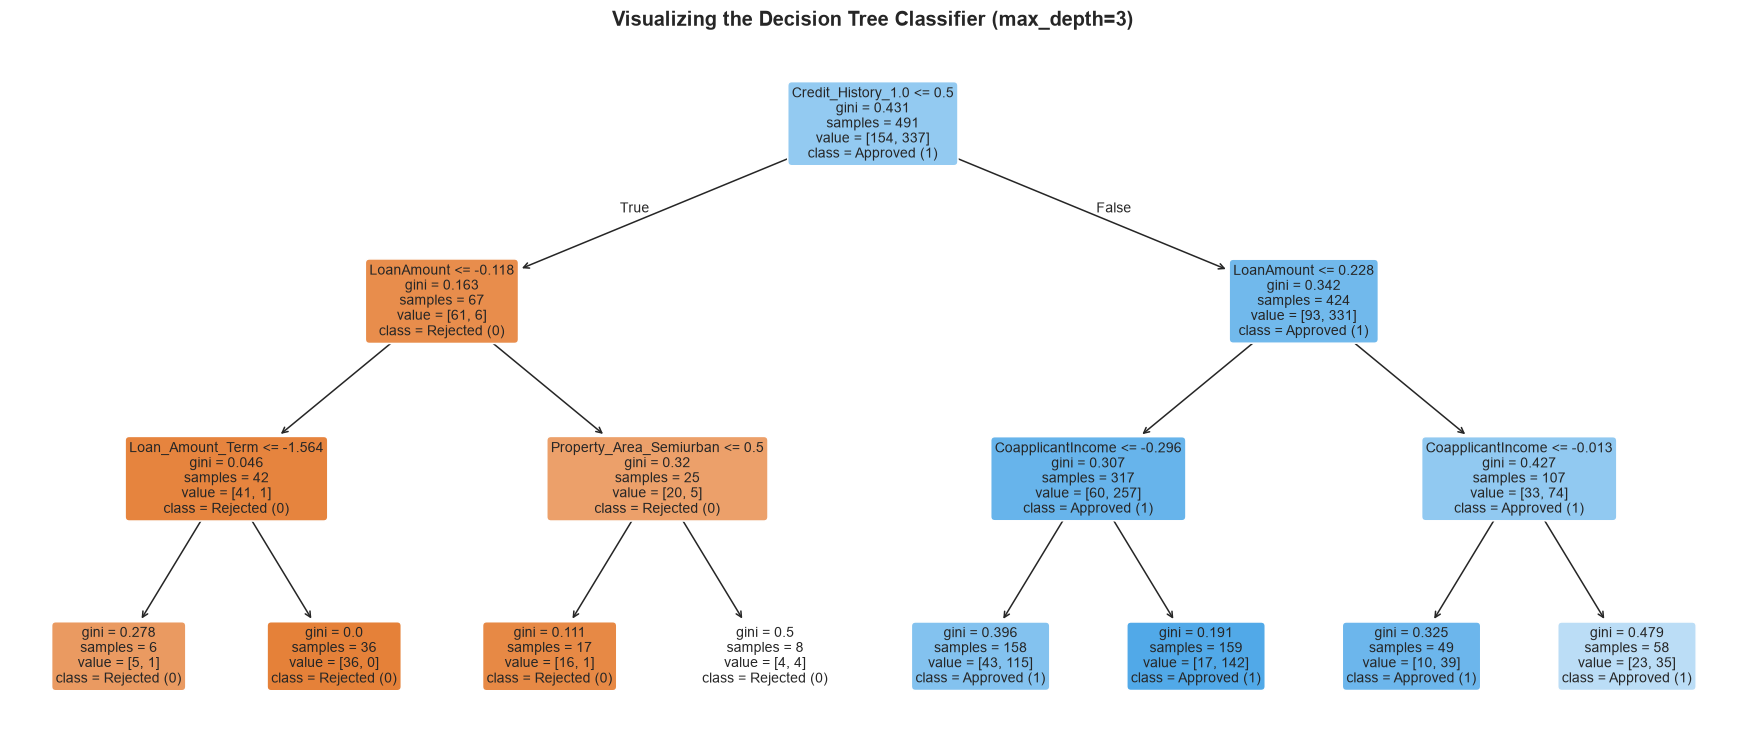

In [26]:
# Compare Unconstrained Decision Tree vs. Pruned Decision Tree to demonstrate overfitting control
dt_unconstrained = DecisionTreeClassifier(random_state=42)
dt_unconstrained.fit(X_train_scaled, y_train)
print(f"⚠️ Unconstrained Decision Tree (max_depth=None) -> Train Acc: {dt_unconstrained.score(X_train_scaled, y_train):.4f} | Test Acc: {dt_unconstrained.score(X_test_scaled, y_test):.4f} (Overfitting!)\n")

# 2. Train Well-Regularized Decision Tree Classifier (تدريب نموذج شجرة القرار)
dt_clf = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, criterion="gini", random_state=42)
dt_clf.fit(X_train_scaled, y_train)

y_train_pred_dt = dt_clf.predict(X_train_scaled)
y_test_pred_dt  = dt_clf.predict(X_test_scaled)
y_test_prob_dt  = dt_clf.predict_proba(X_test_scaled)[:, 1]

evaluate_classification_model(
    "2. Decision Tree Classifier",
    y_train, y_train_pred_dt,
    y_test, y_test_pred_dt,
    y_test_prob_dt
)

# Visualize the Decision Tree structure
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    dt_clf,
    feature_names= list(X_train_scaled.columns),
    class_names=["Rejected (0)", "Approved (1)"],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax
)
ax.set_title("Visualizing the Decision Tree Classifier (max_depth=3)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 9.3 Model 3: Random Forest Classifier (Required)
**How It Works Here:**
- **Random Forest** builds an ensemble of multiple Decision Trees (`n_estimators=100`) trained on bootstrapped subsets of the training data and random subsets of features, combining their predictions by majority vote.
- This significantly reduces variance compared to a single unpruned tree while capturing non-linear relationships across income, loan amount, property area, and credit history.

In [27]:
# 3. Train Random Forest Classifier (تدريب نموذج الغابات العشوائية)
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=3,
    random_state=42
)
rf_clf.fit(X_train_scaled, y_train)

y_train_pred_rf = rf_clf.predict(X_train_scaled)
y_test_pred_rf  = rf_clf.predict(X_test_scaled)
y_test_prob_rf  = rf_clf.predict_proba(X_test_scaled)[:, 1]

evaluate_classification_model(
    "3. Random Forest Classifier",
    y_train, y_train_pred_rf,
    y_test, y_test_pred_rf,
    y_test_prob_rf
)

📊 3. Random Forest Classifier — Evaluation Summary
  • Train Accuracy : 0.8004 (80.04%)
  • Test Accuracy  : 0.8537 (85.37%)
  • Precision      : 0.8317 (83.17%)
  • Recall         : 0.9882 (98.82%)
  • F1-Score       : 0.9032 (90.32%)
  • ROC-AUC Score  : 0.8146
--------------------------------------------------------------------
Classification Report (Test Set):
              precision    recall  f1-score   support

0 (Rejected)       0.95      0.55      0.70        38
1 (Approved)       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



### 9.4 Model 4: Logistic Regression (Additional Benchmark Model for Classification)
> **📌 Important Note (ملاحظة هامة):**
> **Logistic Regression** is included here as an **additional model** (نموذج إضافي وليس بديلًا عن النماذج المطلوبة) to show the standard probabilistic linear classifier alongside Linear Regression, Decision Tree, and Random Forest. Unlike Linear Regression, Logistic Regression passes the linear combination through the **Sigmoid (Logistic) function** $\sigma(z) = \frac{1}{1 + e^{-z}}$, guaranteeing valid probability estimates strictly within $(0, 1)$ and optimizing **Log-Loss (Cross-Entropy)** rather than Squared Error.

In [28]:
# 4. Train Logistic Regression (Additional Classification Benchmark Model - نموذج إضافي)
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

y_train_pred_log = log_reg.predict(X_train_scaled)
y_test_pred_log  = log_reg.predict(X_test_scaled)
y_test_prob_log  = log_reg.predict_proba(X_test_scaled)[:, 1]

evaluate_classification_model(
    "4. Logistic Regression (Additional)",
    y_train, y_train_pred_log,
    y_test, y_test_pred_log,
    y_test_prob_log
)

📊 4. Logistic Regression (Additional) — Evaluation Summary
  • Train Accuracy : 0.8004 (80.04%)
  • Test Accuracy  : 0.8618 (86.18%)
  • Precision      : 0.8400 (84.00%)
  • Recall         : 0.9882 (98.82%)
  • F1-Score       : 0.9081 (90.81%)
  • ROC-AUC Score  : 0.8486
--------------------------------------------------------------------
Classification Report (Test Set):
              precision    recall  f1-score   support

0 (Rejected)       0.96      0.58      0.72        38
1 (Approved)       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



---
## 10. Model Comparison & Visual Evaluation (مقارنة وتقييم النماذج)

Let's compare all four models side by side using:
1. **Comprehensive Metrics Summary Table**
2. **Confusion Matrices Grid (2×2)**
3. **Performance Metrics Bar Chart & ROC Curves Comparison**
4. **Feature Importance Analysis**

In [29]:
# Create a comprehensive comparison DataFrame for all 4 models
# جدول مقارنة شامل لجميع النماذج الأربعة
results_df = pd.DataFrame(model_results).T
results_df["Overfit_Gap (Train - Test)"] = (results_df["Train Accuracy"] - results_df["Test Accuracy"]).round(4)
print("🏆 Comprehensive Model Performance Comparison:")
display(results_df.sort_values(by=["Test Accuracy", "F1-Score", "ROC-AUC"], ascending=False))

🏆 Comprehensive Model Performance Comparison:


,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC,Overfit_Gap (Train - Test)
4. Logistic Regression (Additional),0.8004,0.8618,0.8400,0.9882,0.9081,0.8486,-0.0614
1. Linear Regression (Threshold=0.5),0.8004,0.8618,0.8400,0.9882,0.9081,0.8474,-0.0614
3. Random Forest Classifier,0.8004,0.8537,0.8317,0.9882,0.9032,0.8146,-0.0533
2. Decision Tree Classifier,0.7984,0.8537,0.8317,0.9882,0.9032,0.7729,-0.0553


### 10.1 Confusion Matrices for All 4 Models

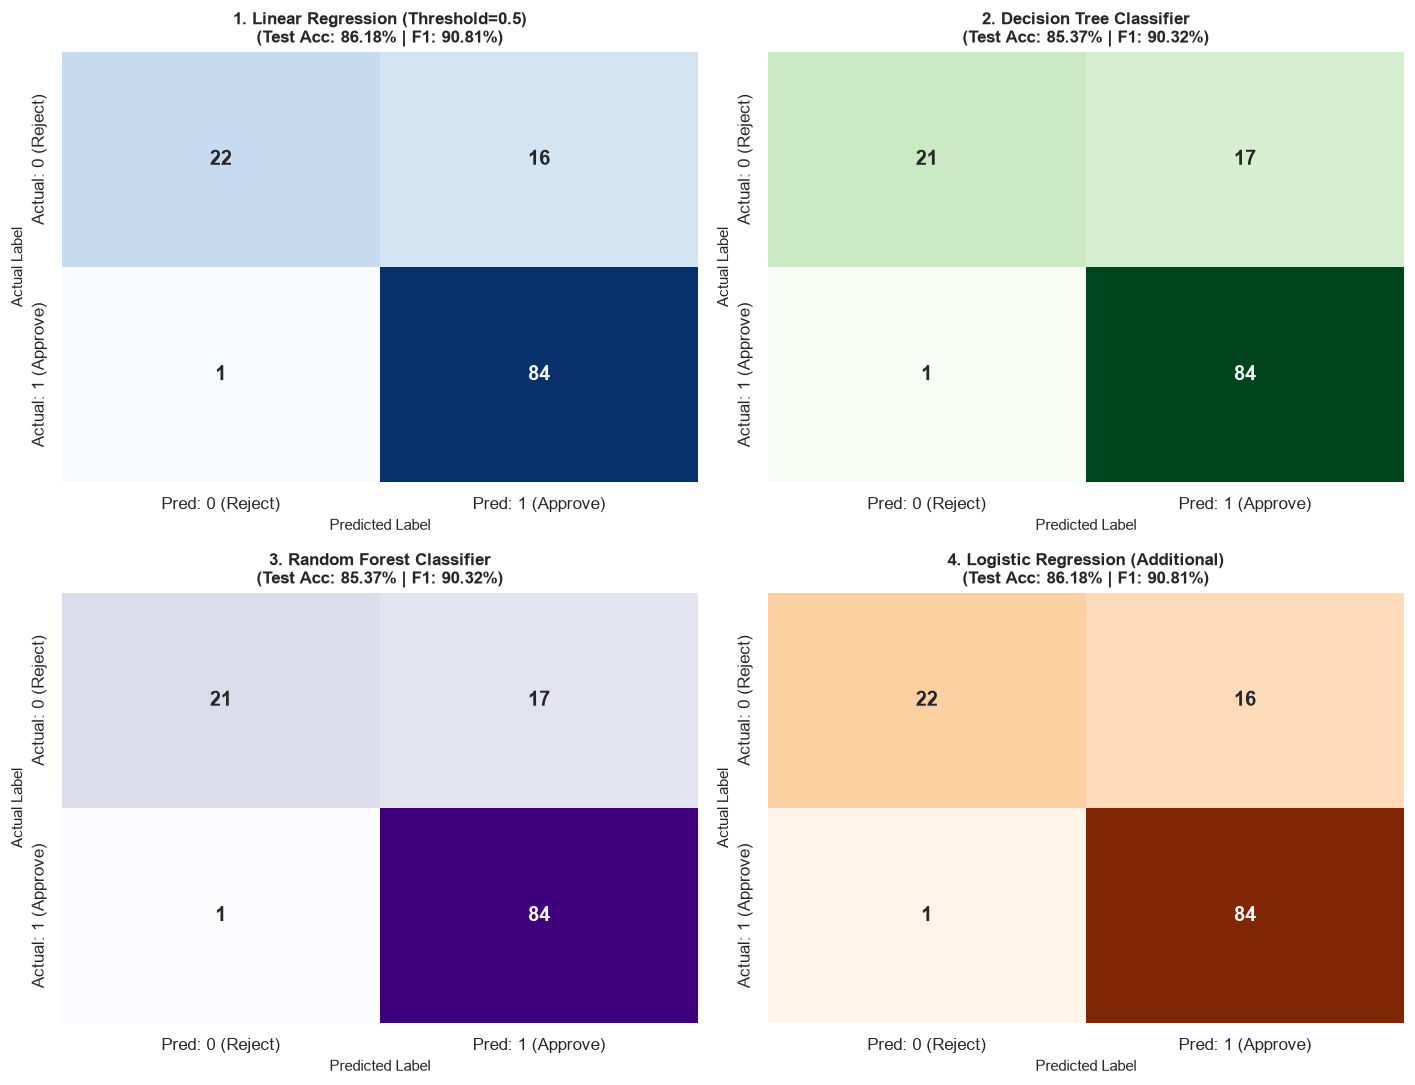

In [30]:
# Plot Confusion Matrices for all 4 models in a 2x2 grid (مصفوفة الارتباك لجميع النماذج)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()
cmaps = ["Blues", "Greens", "Purples", "Oranges"]

for idx, (model_name, y_pred) in enumerate(model_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=cmaps[idx],
        cbar=False,
        xticklabels=["Pred: 0 (Reject)", "Pred: 1 (Approve)"],
        yticklabels=["Actual: 0 (Reject)", "Actual: 1 (Approve)"],
        annot_kws={"size": 13, "weight": "bold"},
        ax=axes[idx]
    )
    acc = model_results[model_name]["Test Accuracy"]
    f1  = model_results[model_name]["F1-Score"]
    axes[idx].set_title(f"{model_name}\n(Test Acc: {acc*100:.2f}% | F1: {f1*100:.2f}%)", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Predicted Label", fontsize=10)
    axes[idx].set_ylabel("Actual Label", fontsize=10)

plt.tight_layout()
plt.show()

### 10.2 Visual Comparison: Metrics Bar Chart & ROC Curves

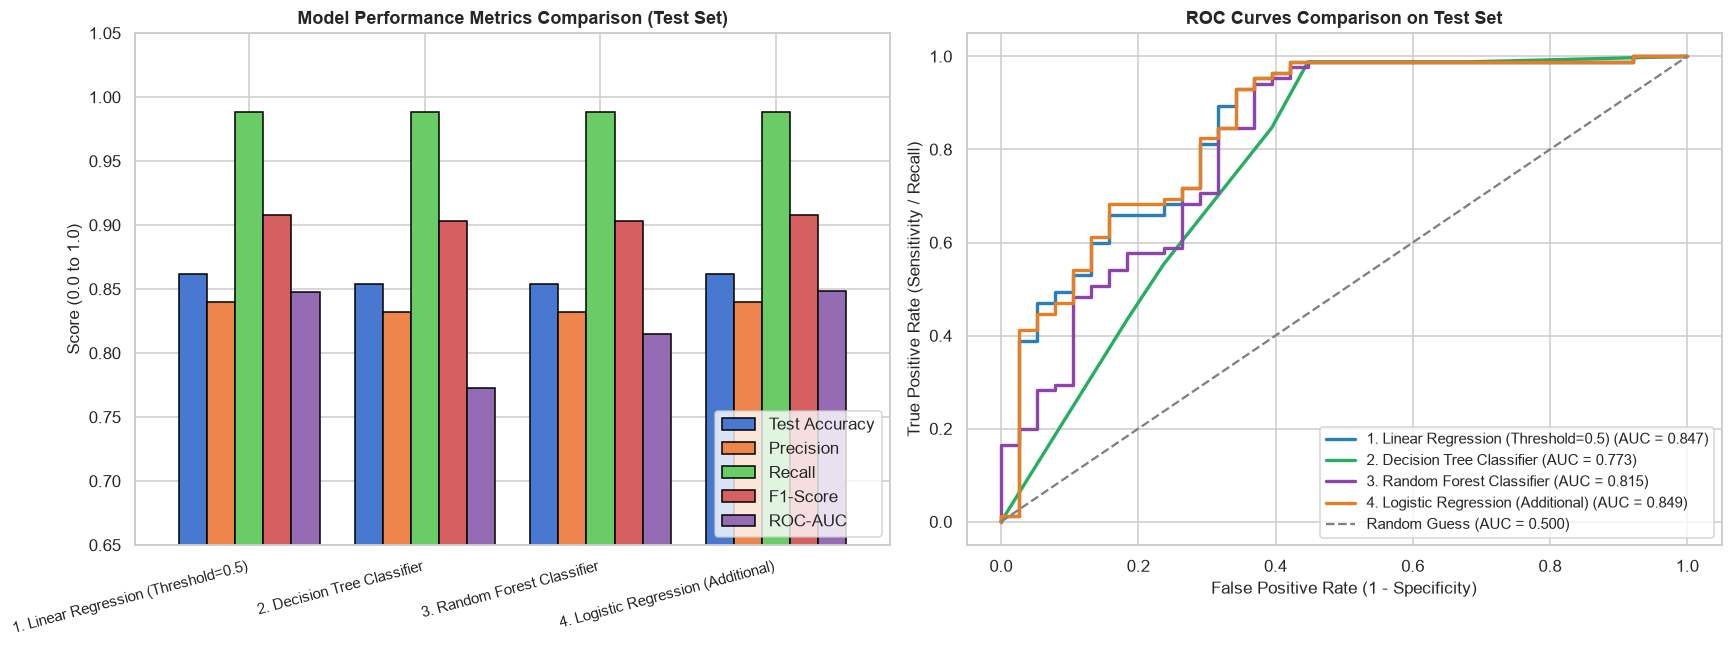

In [31]:
# Plot side-by-side: (Left) Grouped Bar Chart of Metrics, (Right) ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Metrics Comparison Bar Chart
metrics_to_plot = ["Test Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
results_df[metrics_to_plot].plot(kind="bar", ax=axes[0], edgecolor="black", width=0.8)
axes[0].set_title("Model Performance Metrics Comparison (Test Set)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Score (0.0 to 1.0)", fontsize=11)
axes[0].set_ylim(0.65, 1.05)
axes[0].set_xticklabels(results_df.index, rotation=15, ha="right", fontsize=9.5)
axes[0].legend(loc="lower right", frameon=True)

# Right Plot: ROC Curves
colors = ["#2980b9", "#27ae60", "#8e44ad", "#e67e22"]
for idx, (model_name, y_score) in enumerate(model_scores_continuous.items()):
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_val = model_results[model_name]["ROC-AUC"]
    axes[1].plot(fpr, tpr, color=colors[idx], linewidth=2.2, label=f"{model_name} (AUC = {auc_val:.3f})")

axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1.5, label="Random Guess (AUC = 0.500)")
axes[1].set_title("ROC Curves Comparison on Test Set", fontsize=12, fontweight="bold")
axes[1].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[1].set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
axes[1].legend(loc="lower right", fontsize=9.5)

plt.tight_layout()
plt.show()

### 10.3 Feature Importance Analysis (أهمية المتغيرات)
Let's examine which features drive loan approval decisions in **Random Forest** (Gini Importance) and **Logistic Regression** (Standardized Coefficients).

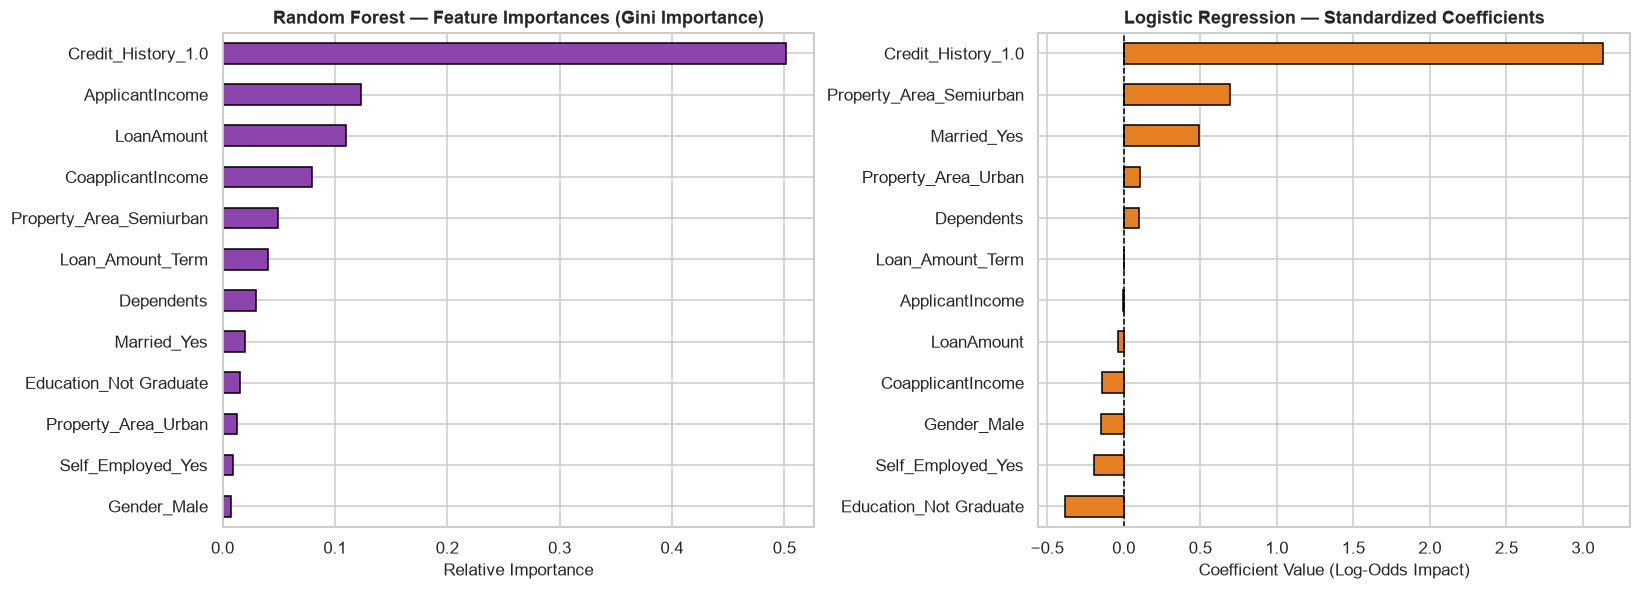

In [32]:
# Feature Importance from Random Forest vs. Standardized Coefficients from Logistic Regression
rf_importances = pd.Series(rf_clf.feature_importances_, index=X_train_scaled.columns).sort_values(ascending=True)
log_coeffs     = pd.Series(log_reg.coef_[0], index=X_train_scaled.columns).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Random Forest Feature Importance
rf_importances.plot(kind="barh", color="#8e44ad", edgecolor="black", ax=axes[0])
axes[0].set_title("Random Forest — Feature Importances (Gini Importance)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Relative Importance", fontsize=11)

# Logistic Regression Coefficients
log_coeffs.plot(kind="barh", color="#e67e22", edgecolor="black", ax=axes[1])
axes[1].axvline(0, color="black", linewidth=1, linestyle="--")
axes[1].set_title("Logistic Regression — Standardized Coefficients", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Coefficient Value (Log-Odds Impact)", fontsize=11)

plt.tight_layout()
plt.show()

---
## 11. Final Conclusion & Technical Insights (الخاتمة والملخص النهائي)

### 📌 Summary of Results on the Test Set (`123` Unseen Applications):
1. **Top Classification Accuracy (`86.18%` / `85.37%`) & F1-Score (`90.81%` / `90.32%`):**
   - **Logistic Regression (`86.18%` Accuracy, `90.81%` F1-Score, `0.8486` ROC-AUC)** and **Linear Regression with `0.5` Threshold (`86.18%` Accuracy, `90.81%` F1-Score, `0.8474` ROC-AUC)** achieved the highest test metrics, closely followed by **Random Forest Classifier (`85.37%` Accuracy, `90.32%` F1-Score, `0.8146` ROC-AUC)** and **Regularized Decision Tree (`85.37%` Accuracy, `90.32%` F1-Score, `0.7729` ROC-AUC)**.
   - Across all models, `Credit_History` is the single dominant rule: applicants with `Credit_History = 0.0` are almost always rejected (`21` to `22` True Negatives out of `38` actual rejections), whereas applicants with `Credit_History = 1.0` and Semiurban property locations have the highest probability of approval (`84` True Positives out of `85` actual approvals).

### 📌 Why We Use Classification Models Instead of Linear Regression in Production:
Even though **Linear Regression with a `0.5` threshold** produced competitive accuracy on this specific dataset (because the decision boundary is heavily dominated by the binary variable `Credit_History`), Linear Regression is **not** theoretically suitable for classification in general because:
1. **Unbounded Outputs:** Linear Regression produces values outside $[0, 1]$ (e.g., greater than `1.0` or negative), which cannot be interpreted as valid probabilities.
2. **Sensitivity to Extreme Values in $X$:** A single extreme income outlier can tilt the Ordinary Least Squares regression hyperplane and shift the `0.5` threshold boundary.
3. **Non-Constant Variance (Heteroscedasticity):** Binary targets violate the Gaussian homoscedastic error assumptions of Linear Regression.
4. **Superiority of Logistic Regression & Random Forest:** **Logistic Regression** bounds probabilities within $(0, 1)$ via the Sigmoid function, while **Random Forest** captures non-linear feature interactions (such as income-to-loan ratios) without overfitting.